<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [116]:
#Importation des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

In [117]:
#Affichage de toutes les colonnes d'un dataframe
pd.options.display.max_columns = None
pd.options.display.max_rows = None

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [118]:
#Importation des fichiers
df_web = pd.read_excel("web.xlsx")
df_erp = pd.read_excel("erp.xlsx")
df_liaison = pd.read_excel("liaison.xlsx")

/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning:

Unknown extension is not supported and will be removed

/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning:

Unknown extension is not supported and will be removed

/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning:

Unknown extension is not supported and will be removed



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [119]:
#Dimensions du dataset
print("Le tableau comporte {} ligne(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))

Le tableau comporte 825 ligne(s)
Le tableau comporte 6 colonne(s)


In [120]:
#Nature des données
df_erp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    object 
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), object(1)
memory usage: 38.8+ KB


In [121]:
#5 premières lignes de la table
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse de la variable product_id
</h3>
</div>

In [122]:
#Vérification des doublons dans la colonne product_id
print("La colonne product_ID comporte {} doublon(s)".format(df_erp.duplicated("product_id").sum()))

La colonne product_ID comporte 0 doublon(s)


La variable "product_ID" identifie de manière unique chaque ligne du dataset, c'est une clé candidate pour ce dataset.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.2 - Analyse de la variable stock_status
</h3>
</div>

In [123]:
#Valeurs distinctes de la colonne stock_status
print("Les valeurs distinctes de la colonnes stock_status sont : {}".format(df_erp ["stock_status"].unique()))
print("Elle sont liées à la colonne {}. Si la valeur est nulle alors le statut est 'outofstock' sinon le statut est 'instock'".format("stock_quantity"))

Les valeurs distinctes de la colonnes stock_status sont : ['instock' 'outofstock']
Elle sont liées à la colonne stock_quantity. Si la valeur est nulle alors le statut est 'outofstock' sinon le statut est 'instock'


In [124]:
#Analyse de la colonne stock_status
#Création d'une cne "stock_status_2" : règle de statut de stock : stock_quantity = 0 alors "outofstock" sinon "instock"
df_erp["stock_status_2"] = "instock"
df_erp.loc[df_erp["stock_quantity"]<=0, ["stock_status_2"]] ="outofstock"

In [125]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
(df_erp["stock_status"] == df_erp["stock_status_2"]).head()

,0
0,True
1,True
2,True
3,True
4,False


In [126]:
#Calcul de la somme des colonnes :
print("le nombre de lignes conformes est de {}".format((df_erp["stock_status"] == df_erp["stock_status_2"]).sum()))
print("Nous devrions obtenir la somme de {} qui correspond au nombre de lignes dans ce dataset".format((df_erp.shape[0])))

le nombre de lignes conformes est de 823
Nous devrions obtenir la somme de 825 qui correspond au nombre de lignes dans ce dataset


In [127]:
#Vérification du statut de stock et detection des anomalies
df_erp.loc[df_erp["stock_status"] != df_erp["stock_status_2"], :]


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
4,4039,1,46.0,3,outofstock,23.77,instock
398,4885,1,18.7,0,instock,9.66,outofstock


**ANOMALIE 1** : incohérence `stock_statut` et `stock_quantity`

In [128]:
#CORRECTION des données incohérentes : ANOMALIE 1
df_erp.loc[df_erp["product_id"] == 4039, "stock_status"] = "instock"
df_erp.loc[df_erp["product_id"] == 4885, "stock_status"] = "outofstock"

#VERIFICATION
print("le nombre de lignes conformes est de {}".format((df_erp["stock_status"] == df_erp["stock_status_2"]).sum()))
print("Nous devrions obtenir la somme de {} qui correspond au nombre de lignes dans ce dataset".format((df_erp.shape[0])))

le nombre de lignes conformes est de 825
Nous devrions obtenir la somme de 825 qui correspond au nombre de lignes dans ce dataset


In [129]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante avec la colonne "stock_status"
df_erp = df_erp.drop(columns=['stock_status_2'])

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.3 - Analyse de la variable PRIX</h3>
</div>

In [130]:
#Afficher le ou les prix non renseignés dans la colonne "price"
print("Nombres d'articles avec un prix non renseigné est de {}".format(df_erp["price"].isnull().sum()))
#Afficher le prix minimum de la colonne "price"
print("le prix minimun est {}".format(df_erp["price"].min()))
#Afficher le prix maximum de la colonne "price"
print("le prix maximum est {}".format(df_erp["price"].max()))
#Afficher le nombre d'articles avec un prix inférieurs à 0
print("Le nombre d'articles avec un prix inférieur ou égal à 0 est de {}".format(df_erp.loc[df_erp["price"] <= 0].shape[0]))
print("le nombre d'articles avec un prix supérieur ou égale à 0 est de {}".format((df_erp["price"] >= 0).sum()))
print("Nous devrions obtenir la somme de {} qui correspond au nombre de lignes dans ce dataset".format((df_erp.shape[0])))

Nombres d'articles avec un prix non renseigné est de 0
le prix minimun est -20.0
le prix maximum est 225.0
Le nombre d'articles avec un prix inférieur ou égal à 0 est de 3
le nombre d'articles avec un prix supérieur ou égale à 0 est de 822
Nous devrions obtenir la somme de 825 qui correspond au nombre de lignes dans ce dataset


In [131]:
#Afficher les prix inférieurs à 0
df_erp.loc[df_erp["price"]<= 0, ["product_id","price","stock_quantity"]]


,product_id,price,stock_quantity
151,4233,-20.0,0
469,5017,-8.0,0
739,6594,-9.1,19


**ANOMALIE 2** : prix négatifs détectés

In [132]:
#CORRECTION des données incohérentes : ANOMALIE 2
#Action métier : transmettre la liste au métier pour vérification et correction
#Action Data Analyst : Suppression des lignes dont le prix est inférieur ou égal à 0 pour fiabiliser l'analyse
df_erp = df_erp[df_erp["price"] > 0]

#VERIFICATION
print("le nombre de lignes avec un prix supérieur ou égale à 0 est de {}".format((df_erp["price"] >= 0).sum()))
print("Nous devrions obtenir la somme de {} qui correspond au nombre de lignes dans ce dataset après correction".format((df_erp.shape[0])))

le nombre de lignes avec un prix supérieur ou égale à 0 est de 822
Nous devrions obtenir la somme de 822 qui correspond au nombre de lignes dans ce dataset après correction


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.4 - Analyse de la variable STOCK</h3>
</div>

In [133]:
#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
print("La quantité minimun de la colonne stock_quantity est de {}".format(df_erp["stock_quantity"].min()))
#Afficher la quantité maximum de la colonne "stock_quantity"
print("La quantité maximum de la colonne stock_quantity est de {}".format(df_erp["stock_quantity"].max()))
#Afficher le nombre d'article avec un stock inférieur à 0 (qu'est-ce qu'il faut en faire ?)
print("Le nombre d'article avec un stock inférieur à 0 est de {}".format((df_erp["stock_quantity"]< 0).sum()))
print("le nombre d'articles avec un stock supérieur ou égale à 0 est de {}".format((df_erp["stock_quantity"] >= 0).sum()))
print("Nous devrions obtenir la somme de {} qui correspond au nombre de lignes dans ce dataset".format((df_erp.shape[0])))

La quantité minimun de la colonne stock_quantity est de -10
La quantité maximum de la colonne stock_quantity est de 145
Le nombre d'article avec un stock inférieur à 0 est de 2
le nombre d'articles avec un stock supérieur ou égale à 0 est de 820
Nous devrions obtenir la somme de 822 qui correspond au nombre de lignes dans ce dataset


In [134]:
#Afficher les stocks inférieurs à 0
df_erp.loc[df_erp["stock_quantity"]< 0, ["product_id","stock_quantity"]]

,product_id,stock_quantity
449,4973,-10
573,5700,-1


**ANOMALIE 3** : stocks négatifs détectés

In [135]:
#CORRECTION des données incohérentes : ANOMALIE 3
#Action métier : transmettre la liste au métier pour vérification et correction
#Action Data Analyst : Suppression des lignes dont le stock est inférieur  à 0 pour fiabiliser l'analyse
df_erp = df_erp[df_erp["stock_quantity"] >= 0]

#VERIFICATION
print("le nombre d'articles avec un stock supérieur ou égale à 0 est de {}".format((df_erp["stock_quantity"] >= 0).sum()))
print("Nous devrions obtenir la somme de {} qui correspond au nombre de lignes dans ce dataset après correction".format((df_erp.shape[0])))

le nombre d'articles avec un stock supérieur ou égale à 0 est de 820
Nous devrions obtenir la somme de 820 qui correspond au nombre de lignes dans ce dataset après correction


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.5 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [136]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient.
print("Les valeurs distinctes de la colonnes onsale_web sont : {}".format(df_erp ["onsale_web"].unique()))
print ("""La colonne onsale_web indique que des produits sont proposés à la vente sur le site web
        1 : produit disponible à la vente sur le site web
        0 : produit non disponible à la vente sur le site web """)

Les valeurs distinctes de la colonnes onsale_web sont : [1 0]
La colonne onsale_web indique que des produits sont proposés à la vente sur le site web
        1 : produit disponible à la vente sur le site web
        0 : produit non disponible à la vente sur le site web 


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.6 - Analyse de la variable prix d'achat</h3>
</div>

In [137]:
#Vérification de la colonne purchase_price :
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print("Nombres d'articles avec un prix d'achat non renseigné: {}".format(df_erp["purchase_price"].isnull().sum()))
#Afficher le prix minimum de la colonne "purchase_price"
print("le prix d'achat minimun est {}".format(df_erp["purchase_price"].min()))
#Afficher le prix maximum de la colonne "purchase_price"
print("le prix maximum d'achat est {}".format(df_erp["purchase_price"].max()))
#Afficher le nombre d'articles avec un prix inférieurs à 0
print("Le nombre d'articles avec un prix d'achat inférieur ou égal à 0 est de {}".format(df_erp.loc[df_erp["purchase_price"] <= 0].shape[0]))
print("le nombre d'articles avec un prix d'achat supérieur ou égale à 0 est de {}".format((df_erp["purchase_price"] >= 0).sum()))
print("Nous devrions obtenir la somme de {} qui correspond au nombre de lignes dans ce dataset".format((df_erp.shape[0])))

Nombres d'articles avec un prix d'achat non renseigné: 0
le prix d'achat minimun est 2.74
le prix maximum d'achat est 137.81
Le nombre d'articles avec un prix d'achat inférieur ou égal à 0 est de 0
le nombre d'articles avec un prix d'achat supérieur ou égale à 0 est de 820
Nous devrions obtenir la somme de 820 qui correspond au nombre de lignes dans ce dataset


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>


In [138]:
#Dimension du dataset
print("Le tableau comporte {} ligne(s)".format(df_web.shape[0]))
print("Le tableau comporte {} colonnes(s)".format(df_web.shape[1]))

Le tableau comporte 1513 ligne(s)
Le tableau comporte 29 colonnes(s)


In [139]:
#Nature des données
df_web.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    object        
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[ns]
 10  post_date_gmt          1430 non-null   datetime64[ns]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   object        
 13  pos

In [140]:
#5 premières lignes de la table
df_web.head()

,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
0,11862,0,0,0,0.0,3.0,NaN,NaN,2.0,2018-02-12 13:46:23,2018-02-12 12:46:23,NaN,Vin,Gilles Robin Hermitage Rouge 2012,NaN,publish,closed,closed,NaN,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
1,16057,0,0,0,0.0,5.0,NaN,NaN,2.0,2018-04-17 15:29:17,2018-04-17 13:29:17,NaN,Vin,Domaine Pellé Sancerre Rouge La Croix Au Garde...,NaN,publish,closed,closed,NaN,pelle-sancerre-rouge-la-croix-au-garde-2017,2020-07-07 10:05:02,2020-07-07 08:05:02,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
2,14692,0,0,0,0.0,5.0,taxable,NaN,2.0,2019-03-19 10:06:47,2019-03-19 09:06:47,NaN,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,<div>Grâce à la complémentarité des 3 cépages ...,publish,closed,closed,NaN,fonreaud-bordeaux-blanc-le-cygne-2016,2020-04-25 21:40:31,2020-04-25 19:40:31,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
3,16295,0,0,0,0.0,14.0,NaN,NaN,2.0,2018-02-15 14:05:06,2018-02-15 13:05:06,NaN,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,NaN,publish,closed,closed,NaN,moulin-de-gassac-igp-pays-dherault-guilhem-ros...,2020-08-27 18:55:03,2020-08-27 16:55:03,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
4,15328,0,0,0,0.0,2.0,taxable,NaN,2.0,2019-03-27 18:05:09,2019-03-27 17:05:09,NaN,Vin,Agnès Levet Côte Rôtie Maestria 2017,"<span style=""float: none; background-color: tr...",publish,closed,closed,NaN,agnes-levet-cote-rotie-maestria-2017,2020-07-25 15:45:02,2020-07-25 13:45:02,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0


<div style="border: 1px solid RGB(51,165,182);" >

---


<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2.1 - Analyse de la variable sku </h3>
</div>


In [141]:
#Vérifier s'il y a des lignes en doublon dans la colonne sku
print("La colonne sku comporte {} doublon(s)".format(df_web.duplicated("sku").sum()))
#Vérifier s'il y'a des valeurs manquantes dans la colonne sku
print("Le nombre de valeurs manquantes dans la colonne 'sku' est de {}".format(df_web['sku'].isna().sum()))
# Vérifier le nombre de doublons dans la colonne 'sku' (hors valeurs manquantes)
nb_doublons = df_web[df_web["sku"].notna()].duplicated("sku").sum()
print("La colonne 'sku' comporte {} doublon(s). Les valeurs manquantes sont exlues".format(nb_doublons))

La colonne sku comporte 798 doublon(s)
Le nombre de valeurs manquantes dans la colonne 'sku' est de 85
La colonne 'sku' comporte 714 doublon(s). Les valeurs manquantes sont exlues


Vérification des doublons dans un premier temps et des valeurs manquantes dans un second temps

In [142]:
###### SKU : DOUBLON ########

#exploration des doublons - vérification d'un article
df_web.loc[df_web["sku"] == 11862]

,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
0,11862,0,0,0,0.0,3.0,NaN,NaN,2.0,2018-02-12 13:46:23,2018-02-12 12:46:23,NaN,Vin,Gilles Robin Hermitage Rouge 2012,NaN,publish,closed,closed,NaN,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
1001,11862,0,0,0,0.0,3.0,taxable,NaN,2.0,2018-02-12 13:46:23,2018-02-12 12:46:23,NaN,Vin,Gilles Robin Hermitage Rouge 2012,Une robe rubis intense avec une très belle bri...,publish,closed,closed,NaN,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0


Les doublons de sku viennent des lignes "post_type = attachment" (ce sont des images WordPress, pas des produits cf  "post_mime_type"). On les exclut et on garde uniquement `post_type = product`.

**ANOMALIE 4** : détéction de doublons sur la colonne `sku`

In [143]:
#Avant correction de l'anomalie #4, contrôlons la cohérence de total_sales des SKU en doublon
doublon_sku_sales = df_web.pivot_table (index="sku", columns= "post_type", values= "total_sales",aggfunc="sum")
doublon_sku_sales.head()

post_type,attachment,product
sku,,
38,10.0,10.0
41,6.0,6.0
304,8.0,8.0
523,0.0,0.0
531,8.0,8.0


In [144]:
#vérification des incohérences de total_sales entre post_type product et attachement
doublon_sku_sales.loc[doublon_sku_sales["attachment"] != doublon_sku_sales["product"]]

post_type,attachment,product
sku,,
1366,116.0,6.0
14561,111.0,11.0
14950,122.0,22.0
15346,22.0,2.0


Contrôle cohérence des SKU en doublon :
4 articles présentent une différence de `total_sales` entre les lignes attachment" et "product".
Ces écarts seront transmis au métier pour vérification.
Les lignes de type 'attachment' sont supprimées afin de conserver uniquement les lignes de type "product"

In [145]:
#CORRECTION des SKU en doublon : ANOMALIE 4
# Action Data Analyst : suppression des lignes "attachment" pour concerver une ligne par sku
print("Le nombre de lignes en doublon (type 'attachment') à supprimer est de {}".format(df_web.loc[df_web["post_type"] == "attachment"].shape[0]))
print("Nombre de lignes avant suppression :", df_web.shape[0])
#Suppression des lignes :
df_web = df_web.loc[df_web["post_type"] != "attachment"]
#VERIFICATION :
print("Le nombre de lignes après suppression :", df_web.shape[0])

Le nombre de lignes en doublon (type 'attachment') à supprimer est de 714
Nombre de lignes avant suppression : 1513
Le nombre de lignes après suppression : 799


In [146]:
###### SKU - VALEURS MANQUANTES ########

#Identifier les lignes sans code article

#1 - Créer un dataframe avec uniquement les lignes sans code article
df_sku_na = df_web.loc[df_web["sku"].isna()]
df_sku_na.info()

<class 'pandas.core.frame.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    0 non-null      object        
 1   virtual                85 non-null     int64         
 2   downloadable           85 non-null     int64         
 3   rating_count           85 non-null     int64         
 4   average_rating         2 non-null      float64       
 5   total_sales            2 non-null      float64       
 6   tax_status             2 non-null      object        
 7   tax_class              0 non-null      float64       
 8   post_author            2 non-null      float64       
 9   post_date              2 non-null      datetime64[ns]
 10  post_date_gmt          2 non-null      datetime64[ns]
 11  post_content           0 non-null      float64       
 12  product_type           2 non-null      object        
 13  post_title

Constat après observation des valeurs renseignées dans le DataFrame `df_sku_na` : sur 85 lignes sans numéro de sku, 2 comportent malgré tout des ventes.

In [147]:
#Vérification des 2 lignes avec des valeurs dans la variables total_sales et sans numéro de sku
df_sku_na.loc[df_sku_na["total_sales"].notna()]

,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
1084,NaN,0,0,0,0.0,-56.0,taxable,NaN,2.0,2018-08-08 11:23:43,2018-08-08 09:23:43,NaN,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,"<span id=""u1194-83"">Le nez séduit par ses parf...",publish,closed,closed,NaN,pierre-jean-villa-condrieu-suspendu-2018,2019-11-02 13:24:01,2019-11-02 12:24:01,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
1087,NaN,0,0,0,0.0,-17.0,taxable,NaN,2.0,2018-07-31 12:07:23,2018-07-31 10:07:23,NaN,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017,"Fongeant 2017 explose sur un fruit brillant, p...",publish,closed,closed,NaN,pierre-jean-villa-cote-rotie-fongeant-2017,2019-11-02 13:24:15,2019-11-02 12:24:15,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0


**ANOMALIE 5** : détection de 2 lignes avec des ventes négatives et sans numéro de sku.

In [148]:
#Vérifions les lignes non vides des colonnes virtual, downloadable et rating_count
df_sku_na[["virtual", "downloadable" ,"rating_count"]].head()

,virtual,downloadable,rating_count
8,0,0,0
20,0,0,0
30,0,0,0
37,0,0,0
41,0,0,0


In [149]:
#Vérifions la sommes des valeurs des 3 colonnes, il semble qu'il n y'ait que des 0
df_sku_na[["virtual", "downloadable" ,"rating_count"]].sum()

,0
virtual,0
downloadable,0
rating_count,0


Les colonnes `virtual`, `downloadable` et `rating_count` ne contiennent que des 0 partout : elles ne servent à rien pour l'analyse, on les supprime.

In [150]:
#CORRECTION de l'ANOMALIES #5
#Action métier : transmettre la liste des 2 lignes sans numéro de sku avec des ventes négatives au métier pour vérification et correction
#Action Data Analyst : suppression de toutes les lignes sans numéro de sku car elles n'apportent pas d'information pertinente à l'analyse
print("Le nombre de valeurs manquantes dans la colonne 'sku' est de {}".format(df_web['sku'].isna().sum()))
#Suppression des lignes :
df_web = df_web.loc[df_web["sku"].notna()]
#VERIFICATION
print("Le nombre de valeurs manquantes après correction des anomalie #5 et #6 est de {}".format(df_web['sku'].isna().sum()))

Le nombre de valeurs manquantes dans la colonne 'sku' est de 85
Le nombre de valeurs manquantes après correction des anomalie #5 et #6 est de 0


In [151]:
#Analyse des valeurs qui ne semblent pas respecter la régle de codification
#Modification de la colonne "sku" en chaîne de caractères pour compter le nombre de caractères de chaque SKU
df_web["sku"] = df_web["sku"].astype(str)

In [152]:
#Nombre de caractère de chaque valeur différent de 5 (5 = règle de codif soit le nombre de caractère standard observé)
print("Le nombre de sku avec un format à 5 caractères est de {}".format((df_web["sku"].str.len() == 5).sum()))
df_web.loc[df_web["sku"].str.len() != 5].head()


Le nombre de sku avec un format à 5 caractères est de 671


,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
33,9636,0,0,0,0.0,0.0,taxable,NaN,2.0,2018-03-22 10:44:57,2018-03-22 09:44:57,NaN,Whisky,Wemyss Malts Blended Malt Scotch Whisky The Hi...,The Hive est un assemblage de malts du Speysid...,publish,closed,closed,NaN,whisky-wemyss-the-hive-12-ans,2020-08-19 17:45:03,2020-08-19 15:45:03,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
48,804,0,0,0,0.0,3.0,taxable,NaN,2.0,2018-04-14 11:59:32,2018-04-14 09:59:32,NaN,Vin,Marcel Windholtz Eau de Vie de Mirabelle d'Als...,Les eaux de vie naissent d'une subtile alchimi...,publish,closed,closed,NaN,marcel-windholtz-eau-de-mirabelle-dalsace-rese...,2020-07-23 10:15:03,2020-07-23 08:15:03,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
167,9937,0,0,0,0.0,2.0,taxable,NaN,2.0,2018-05-17 12:55:13,2018-05-17 10:55:13,NaN,Vin,Marcel Richaud Cairanne Rouge Les Estrambords ...,"Un vin généreux, profond et intense. Les notes...",publish,closed,closed,NaN,marcel-richaud-cairanne-rouge-les-estrambords-...,2019-06-26 09:32:25,2019-06-26 07:32:25,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
194,3509,0,0,0,0.0,5.0,taxable,NaN,2.0,2018-03-22 11:49:53,2018-03-22 10:49:53,NaN,Cognac,Cognac Frapin Cigar Blend,Ce cognac bénéficie d'un vieillissement plus l...,publish,closed,closed,NaN,cognac-frapin-cigar-blend,2020-07-04 09:45:03,2020-07-04 07:45:03,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
195,2534,0,0,0,0.0,4.0,taxable,NaN,2.0,2018-04-14 11:50:29,2018-04-14 09:50:29,NaN,Vin,Marcel Windholtz Eau de Vie de Fraise,Les eaux de vie naissent d'une subtile alchimi...,publish,closed,closed,NaN,marcel-windholtz-eau-de-vie-de-fraise,2020-08-21 15:45:04,2020-08-21 13:45:04,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0


In [153]:
#vérification des sku avec caractère supérieur à 5
print("Le nombre de sku avec un format supérieur à 5 caractères est de {}".format((df_web["sku"].str.len() > 5).sum()))
df_web.loc[df_web["sku"].str.len() > 5]

Le nombre de sku avec un format supérieur à 5 caractères est de 2


,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
272,13127-1,0,0,0,0.0,4.0,taxable,NaN,2.0,2020-06-09 15:42:04,2020-06-09 13:42:04,NaN,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,"Nez gracieux, très élégant avec une touche flo...",publish,closed,closed,NaN,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,2020-07-20 17:09:06,2020-07-20 15:09:06,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
1387,bon-cadeau-25-euros,0,0,0,0.0,7.0,taxable,NaN,1.0,2018-06-01 13:53:46,2018-06-01 11:53:46,NaN,NaN,Bon cadeau de 25€,"<span style=""color: #a85253;""><strong>Parlons ...",publish,closed,closed,NaN,bon-cadeau-de-25-euros,2018-06-01 14:13:57,2018-06-01 12:13:57,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0


In [154]:
#vérification des sku avec caractère inférieur à 5
print("Le nombre de sku avec un format inférieur à 5 caractères est de {}".format((df_web["sku"].str.len() < 5).sum()))
df_web.loc[df_web["sku"].str.len() < 5].head()

Le nombre de sku avec un format inférieur à 5 caractères est de 41


,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
33,9636,0,0,0,0.0,0.0,taxable,NaN,2.0,2018-03-22 10:44:57,2018-03-22 09:44:57,NaN,Whisky,Wemyss Malts Blended Malt Scotch Whisky The Hi...,The Hive est un assemblage de malts du Speysid...,publish,closed,closed,NaN,whisky-wemyss-the-hive-12-ans,2020-08-19 17:45:03,2020-08-19 15:45:03,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
48,804,0,0,0,0.0,3.0,taxable,NaN,2.0,2018-04-14 11:59:32,2018-04-14 09:59:32,NaN,Vin,Marcel Windholtz Eau de Vie de Mirabelle d'Als...,Les eaux de vie naissent d'une subtile alchimi...,publish,closed,closed,NaN,marcel-windholtz-eau-de-mirabelle-dalsace-rese...,2020-07-23 10:15:03,2020-07-23 08:15:03,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
167,9937,0,0,0,0.0,2.0,taxable,NaN,2.0,2018-05-17 12:55:13,2018-05-17 10:55:13,NaN,Vin,Marcel Richaud Cairanne Rouge Les Estrambords ...,"Un vin généreux, profond et intense. Les notes...",publish,closed,closed,NaN,marcel-richaud-cairanne-rouge-les-estrambords-...,2019-06-26 09:32:25,2019-06-26 07:32:25,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
194,3509,0,0,0,0.0,5.0,taxable,NaN,2.0,2018-03-22 11:49:53,2018-03-22 10:49:53,NaN,Cognac,Cognac Frapin Cigar Blend,Ce cognac bénéficie d'un vieillissement plus l...,publish,closed,closed,NaN,cognac-frapin-cigar-blend,2020-07-04 09:45:03,2020-07-04 07:45:03,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
195,2534,0,0,0,0.0,4.0,taxable,NaN,2.0,2018-04-14 11:50:29,2018-04-14 09:50:29,NaN,Vin,Marcel Windholtz Eau de Vie de Fraise,Les eaux de vie naissent d'une subtile alchimi...,publish,closed,closed,NaN,marcel-windholtz-eau-de-vie-de-fraise,2020-08-21 15:45:04,2020-08-21 13:45:04,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0


**ANOMALIE 6**  : codification non homogène.
Il existe 4 formats de codifications :

- sku à 5 caractères en majorité
- sku de 2 à 4 caractères
- sku à plus de 5 caractères qui se termine par -1
- sku : bon-cadeau

Action métier: transmettre la liste au métier afin de vérifier les références concernées et définir une règle de codification unique
Action.
Data Analyst : pas d'action de nettoyage à ce stade

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2.2 - Analyse des variables avec valeurs entièrement vides (0 non-null) </h3>
</div>

In [155]:
#Nature des données
df_web.info()

<class 'pandas.core.frame.DataFrame'>
Index: 714 entries, 2 to 1509
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    714 non-null    object        
 1   virtual                714 non-null    int64         
 2   downloadable           714 non-null    int64         
 3   rating_count           714 non-null    int64         
 4   average_rating         714 non-null    float64       
 5   total_sales            714 non-null    float64       
 6   tax_status             714 non-null    object        
 7   tax_class              0 non-null      float64       
 8   post_author            714 non-null    float64       
 9   post_date              714 non-null    datetime64[ns]
 10  post_date_gmt          714 non-null    datetime64[ns]
 11  post_content           0 non-null      float64       
 12  product_type           713 non-null    object        
 13  post_titl

In [156]:
print("Le nombre de variables ne contenant que des valeurs manquantes est de {}.".format(df_web.isna().all().sum()))

Le nombre de variables ne contenant que des valeurs manquantes est de 5.


5 colonnes sont entièrement vides (`tax_class`, `post_content`, `post_password`, `post_content_filtered`, `post_mime_type`). Ce sont des champs techniques WordPress non utilisés pour les produits. Elles n'apportent aucune information et sont supprimées.

In [157]:
#SUPPRESSION des 5 colonnes :
df_web = df_web.drop(columns=["tax_class","post_content","post_password","post_content_filtered","post_mime_type"])
#VERIFICATION
print("Le nombre de variables ne contenant que des valeurs manquantes est de {}.".format(df_web.isna().all().sum()))

Le nombre de variables ne contenant que des valeurs manquantes est de 0.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2.3 - Analyse des variables ne contenant qu'une seule valeur </h3>
</div>

In [158]:
print("Le dataset compte {} colonne(s) ne contenant qu'une seule valeur".format((df_web.nunique() == 1).sum()))
df_web.nunique()

Le dataset compte 12 colonne(s) ne contenant qu'une seule valeur


,0
sku,714
virtual,1
downloadable,1
rating_count,1
average_rating,1
total_sales,24
tax_status,1
post_author,2
post_date,714
post_date_gmt,714


In [159]:
#Vérification des colonnes ne contenant qu'une seule valeur
df_web[["virtual","downloadable","rating_count","average_rating","tax_status","post_status","comment_status","ping_status","post_parent","menu_order","post_type","comment_count"]].head(10)

,virtual,downloadable,rating_count,average_rating,tax_status,post_status,comment_status,ping_status,post_parent,menu_order,post_type,comment_count
2,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
4,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
6,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
11,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
14,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
15,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
17,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
19,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
21,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0
24,0,0,0,0.0,taxable,publish,closed,closed,0.0,0.0,product,0.0


12 colonnes ne contiennent qu'une seule valeur unique sur tout le dataset (champs techniques WordPress non utilisés pour l'analyse produit). Ces colonnes sont supprimées car elles n'apportent pas d'information utiles à l'analyse

In [160]:
#SUPPRESSION des 12 colonnes :
df_web = df_web.drop(columns=["virtual","downloadable","rating_count","average_rating","tax_status","post_status","comment_status","ping_status","post_parent","menu_order","post_type","comment_count"])
#VERIFICATION :
print("Le dataset compte {} variable(s) ne contenant qu'une seule valeur".format((df_web.nunique() == 1).sum()))

Le dataset compte 0 variable(s) ne contenant qu'une seule valeur


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2.4 - Analyse métier des variables restantes </h3>
</div>

In [161]:
#5 premières lignes de la table
df_web.head()

,sku,total_sales,post_author,post_date,post_date_gmt,product_type,post_title,post_excerpt,post_name,post_modified,post_modified_gmt,guid
2,14692,5.0,2.0,2019-03-19 10:06:47,2019-03-19 09:06:47,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,<div>Grâce à la complémentarité des 3 cépages ...,fonreaud-bordeaux-blanc-le-cygne-2016,2020-04-25 21:40:31,2020-04-25 19:40:31,https://www.bottle-neck.fr/?post_type=product&...
4,15328,2.0,2.0,2019-03-27 18:05:09,2019-03-27 17:05:09,Vin,Agnès Levet Côte Rôtie Maestria 2017,"<span style=""float: none; background-color: tr...",agnes-levet-cote-rotie-maestria-2017,2020-07-25 15:45:02,2020-07-25 13:45:02,https://www.bottle-neck.fr/?post_type=product&...
6,16515,10.0,2.0,2018-06-02 09:31:31,2018-06-02 07:31:31,Vin,Château Turcaud Bordeaux Rouge Cuvée Majeure 2018,"<div id=""wrapper"">\n<div id=""container-wrapper...",chateau-turcaud-bordeaux-rouge-cuvee-majeure-2018,2020-08-27 10:11:12,2020-08-27 08:11:12,https://www.bottle-neck.fr/?post_type=product&...
11,16585,15.0,2.0,2018-02-16 14:03:16,2018-02-16 13:03:16,Vin,Xavier Frissant Touraine Sauvignon 2019,"Un joli sauvignon frais et minéral, avec d'int...",xavier-frissant-touraine-sauvignon-2019,2020-08-27 09:30:36,2020-08-27 07:30:36,https://www.bottle-neck.fr/?post_type=product&...
14,12869,7.0,2.0,2019-03-28 14:29:35,2019-03-28 13:29:35,Vin,Stéphane Tissot Arbois D.D. 2016,"Un Vin coloré et éclatant. Le nez est fruité, ...",stephane-tissot-arbois-dd-2016,2019-12-13 15:40:01,2019-12-13 14:40:01,https://www.bottle-neck.fr/?post_type=product&...


Après relecture de la mission, seules les variables nécessaire aux analyses demandées sont conservées :
- sku
- total_sales
- product_type
- post_title

Les autres variables correspondent principalement à des informations
techniques ou descriptives qui ne sont pas utilisées dans les analyses
demandées. Elles sont donc supprimées du dataset.

In [162]:
#SUPPRESSION des colonnes non utiles pour l'analyse :
df_web = df_web.drop(columns=["post_date","post_author","post_date_gmt","post_excerpt","post_name","post_modified","post_modified_gmt","guid"])

In [163]:
#Vérification des doublons dans la colonne "sku"
print("La colonne sku comporte {} doublon(s)".format(df_web.duplicated("sku").sum()))

La colonne sku comporte 0 doublon(s)


La variable "sku" identifie de manière unique chaque ligne du dataset, c'est une clé candidate pour ce dataset.

In [164]:
#Modificaton du nom de la variable "sku" en "id_web" afin de faciliter les fusions
df_web = df_web.rename(columns={"sku":"id_web"})

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [165]:
#Dimension du dataset
print("Le tableau comporte {} ligne(s)".format(df_liaison.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_liaison.shape[1]))

Le tableau comporte 825 ligne(s)
Le tableau comporte 2 colonne(s)


In [166]:
#La nature des données
df_liaison.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [167]:
#5 premières lignes de la table
df_liaison.head()

,id_web,product_id
0,15298,3847
1,15296,3849
2,15300,3850
3,19814,4032
4,19815,4039


<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3.1 - Analyse de la variable id_web</h3>
</div>

In [168]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?
print("les valeurs de la colonne sont-elles toutes uniques : {}".format(df_liaison["id_web"].is_unique))
print("le nombre d'article avec des valeurs manquantes sont de {}".format(df_liaison["id_web"].isna().sum()))
print("les valeurs de la colonne sont-elles toutes uniques en exluant les valeurs manquantes : {}".format(df_liaison["id_web"].dropna().is_unique))

les valeurs de la colonne sont-elles toutes uniques : False
le nombre d'article avec des valeurs manquantes sont de 91
les valeurs de la colonne sont-elles toutes uniques en exluant les valeurs manquantes : True


In [169]:
#Vérification des articles sans correspondance?
print("le nombre d'articles sans correspondance est de {}. Ce nombre correspond aux articles de la variable id_web avec des valeurs manquantes".format(df_liaison["id_web"].isna().sum()))
df_liaison.loc[df_liaison["id_web"].isna(),["id_web", "product_id"]].head()

le nombre d'articles sans correspondance est de 91. Ce nombre correspond aux articles de la variable id_web avec des valeurs manquantes


,id_web,product_id
19,NaN,4055
49,NaN,4090
50,NaN,4092
119,NaN,4195
131,NaN,4209


91 articles ne disposent pas d'un identifiant "id_web". Cette absence de correspondance sera vérifiée lors de la phase de rapprochement des données.

In [170]:
# Vérification que la variable "id_web" est du même type afin de permettre la fusion des fichiers
df_liaison["id_web"].apply(type).value_counts()

,count
id_web,
<class 'int'>,731
<class 'float'>,91
<class 'str'>,3


**ANOMALIE 7** : la colonne `id_web` contient plusieurs types de données. Cela empêche la jointure avec la colonne `id_web` du fichier Web qui est entièrement au format texte

In [171]:
#Action Data Analyst : conversion de la colonne au format string
df_liaison["id_web"] = df_liaison["id_web"].astype("string")
#VERIFICATION :
df_liaison["id_web"].apply(type).value_counts()

,count
id_web,
<class 'str'>,734
<class 'pandas._libs.missing.NAType'>,91


<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3.2 - Analyse de la variable product_id</h3>
</div>

In [172]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?
print("La colonne product_ID comporte {} doublon(s)".format(df_liaison.duplicated("product_id").sum()))

La colonne product_ID comporte 0 doublon(s)


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [173]:
#Dimensions du dataset avant fusion
print("Le tableau comporte {} ligne(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))
#Fusion des fichiers df_erp et df_liaison
df_merge_erp_liaison = pd.merge(df_erp,df_liaison,on="product_id",how="inner")
df_merge_erp_liaison.head()

Le tableau comporte 820 ligne(s)
Le tableau comporte 6 colonne(s)


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web
0,3847,1,24.2,16,instock,12.88,15298
1,3849,1,34.3,10,instock,17.54,15296
2,3850,1,20.8,0,outofstock,10.64,15300
3,4032,1,14.1,26,instock,6.92,19814
4,4039,1,46.0,3,instock,23.77,19815


In [174]:
#Vérification des dimensions du dataset après fusion
print("Le tableau comporte {} ligne(s)".format(df_merge_erp_liaison.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_merge_erp_liaison.shape[1]))

Le tableau comporte 820 ligne(s)
Le tableau comporte 7 colonne(s)


In [175]:
#Vérification des lignes ne "matchant" pas entre les 2 fichiers
#Affichage des valeurs manquantes de la variable id_web
df_merge_erp_liaison.loc[df_merge_erp_liaison["id_web"].isna()].head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web
19,4055,0,86.1,0,outofstock,37.88,<NA>
49,4090,0,73.0,0,outofstock,33.79,<NA>
50,4092,0,47.0,0,outofstock,25.25,<NA>
119,4195,0,14.1,0,outofstock,7.36,<NA>
131,4209,0,73.5,0,outofstock,33.01,<NA>


Les valeurs manquantes dans la colonne "`id_web`" semblent correspondre à des produits qui ne sont pas vendus sur le site Web. Point à vérifier lors de la jointure avec le fichier Web.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [176]:
#Dimensions du dataset avant fusion
print("Le tableau comporte {} ligne(s)".format(df_merge_erp_liaison.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_merge_erp_liaison.shape[1]))
#Fusionner les datasets df_merge et df_web - choix de la jointure à gauche pour garder dans le data set l'ensemble des références du catalogue issus du fichier ERP
df_merge_all = pd.merge(df_merge_erp_liaison,df_web,on="id_web",how="left")

Le tableau comporte 820 ligne(s)
Le tableau comporte 7 colonne(s)


In [177]:
#Vérification des dimensions du dataset après fusion
print("Le tableau comporte {} ligne(s)".format(df_merge_all.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_merge_all.shape[1]))

Le tableau comporte 820 ligne(s)
Le tableau comporte 10 colonne(s)


In [178]:
#5 premières lignes de la table
df_merge_all.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title
0,3847,1,24.2,16,instock,12.88,15298,6.0,Vin,Pierre Jean Villa Saint-Joseph Préface 2018
1,3849,1,34.3,10,instock,17.54,15296,9.0,Vin,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017
2,3850,1,20.8,0,outofstock,10.64,15300,0.0,Vin,Pierre Jean Villa Crozes-Hermitage Accroche Co...
3,4032,1,14.1,26,instock,6.92,19814,12.0,Vin,Pierre Jean Villa IGP Collines Rhodaniennes Ga...
4,4039,1,46.0,3,instock,23.77,19815,3.0,Vin,Pierre Jean Villa Côte Rôtie Carmina 2017


In [179]:
#Analyse des incohérences après fusions
#Vérification des lignes sans correspondance
print("Le tableau comporte {} ligne(s) sans correspondance".format(df_merge_all[["total_sales","product_type","post_title"]].isna().sum()))

Le tableau comporte total_sales     107
product_type    108
post_title      107
dtype: int64 ligne(s) sans correspondance


In [180]:
#Vérification des produits hors catalogue Web et qui ont un id_web
print("Nombre de références hors catalogue Web avec un id_web : {}".format(df_merge_all.loc[(df_merge_all["onsale_web"] == 0) & (df_merge_all["total_sales"].isna()) & (df_merge_all["id_web"].notna()) ].shape[0] ))
df_merge_all.loc[ (df_merge_all["onsale_web"] == 0) & (df_merge_all["total_sales"].isna()) & (df_merge_all["id_web"].notna())]

Nombre de références hors catalogue Web avec un id_web : 20


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title
192,4289,0,22.8,0,outofstock,11.90,13771,NaN,NaN,NaN
235,4568,0,21.5,0,outofstock,11.22,15065,NaN,NaN,NaN
240,4584,0,32.3,0,outofstock,17.36,14785,NaN,NaN,NaN
354,4741,0,12.4,0,outofstock,6.66,12601,NaN,NaN,NaN
390,4864,0,8.3,0,outofstock,9.99,15154,NaN,NaN,NaN
393,4869,0,17.2,0,outofstock,9.33,14360,NaN,NaN,NaN
423,4921,0,13.8,0,outofstock,7.13,15608,NaN,NaN,NaN
424,4922,0,21.5,0,outofstock,10.55,15586,NaN,NaN,NaN
467,5018,0,15.4,0,outofstock,7.72,15272,NaN,NaN,NaN
470,5021,0,17.1,0,outofstock,8.92,15630,NaN,NaN,NaN


In [181]:
#Vérification des produits hors catalogue Web présents dans les données Web
print("Nombre de références hors catalogue Web présentes dans les données Web: {}".format(df_merge_all.loc[(df_merge_all["onsale_web"] == 0) & (df_merge_all["total_sales"].notna()) & (df_merge_all["id_web"].notna())  ].shape[0]))
df_merge_all.loc[ (df_merge_all["onsale_web"] == 0) &  (df_merge_all["total_sales"].notna()) & (df_merge_all["id_web"].notna())]

Nombre de références hors catalogue Web présentes dans les données Web: 1


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title
123,4200,0,5.8,33,instock,3.12,16295,14.0,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...


In [182]:
#Vérification des produits du catalogue Web sans données de vente
print("Nombre de références du catalogue Web sans données Web : {}".format(df_merge_all.loc[(df_merge_all["onsale_web"] == 1) & (df_merge_all["total_sales"].isna()) ].shape[0]))
df_merge_all.loc[(df_merge_all["onsale_web"] == 1) & (df_merge_all["total_sales"].isna())]

Nombre de références du catalogue Web sans données Web : 3


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title
241,4594,1,144.0,0,outofstock,87.36,<NA>,NaN,NaN,NaN
483,5070,1,84.7,0,outofstock,47.43,<NA>,NaN,NaN,NaN
484,5075,1,43.3,0,outofstock,21.70,<NA>,NaN,NaN,NaN


**ANOMALIE 8** : incohérences suite fusion entre l'ERP, la table de liaison et le catalogue Web

- 20 produits hors catalogue Web possèdent un id_web mais ne sont pas retrouvés dans les données Web.
- 3 produits du catalogue Web sont indiqués comme commercialisés (onsale_web = 1) mais ne disposent d'aucun id_web.
- 1 produit hors catalogue Web (onsale_web = 0) est présent dans les données Web.

Ces écarts montrent que les informations du fichier de liaison ne sont pas totalement cohérent.

Action métier :
Vérifier les références concernées et mettre à jour le statut onsale_web,
la table de liaison et les données du catalogue Web si nécessaire.

Recommandation :
Étudier l'intégration de l'id_web directement dans l'ERP afin de supprimer la table de liaison qui est aujourdh'ui géré manuellement.
Cette évolution permettrait de limiter les manipulations manuelles, de réduire les risques d'erreur et de faciliter les fusions.

Action Data Analyst :
Décision de travailler sur deux DataFrames pour la suite de l'analyse.
- df_merge_all : DataFrame complet après fusion pour les analyses portant sur l'ensemble du catalogue (stocks ...)
- df_merge_web : DataFrame où sont exlues les 107 références sans correspondance Web car elles ne disposent pas des données de vente nécessaires aux analyses

In [183]:
#Création du DataFrame df_merge_web

#Vérification avant création
print("Le nouveau DataFrame devrait contenir {} lignes (820 lignes moins 107 sans correspondance Web).".format(df_merge_all["total_sales"].notna().sum()))

df_merge_web = df_merge_all.loc[df_merge_all["total_sales"].notna()].copy()

#Vérification après création
print("Le Nouveau DataFrame df_merge_web comporte {} lignes(s)".format(df_merge_web.shape[0]))
print("Le Nouveau DataFrame df_merge_web comporte {} colonne(s)".format(df_merge_web.shape[1]))

Le nouveau DataFrame devrait contenir 713 lignes (820 lignes moins 107 sans correspondance Web).
Le Nouveau DataFrame df_merge_web comporte 713 lignes(s)
Le Nouveau DataFrame df_merge_web comporte 10 colonne(s)


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

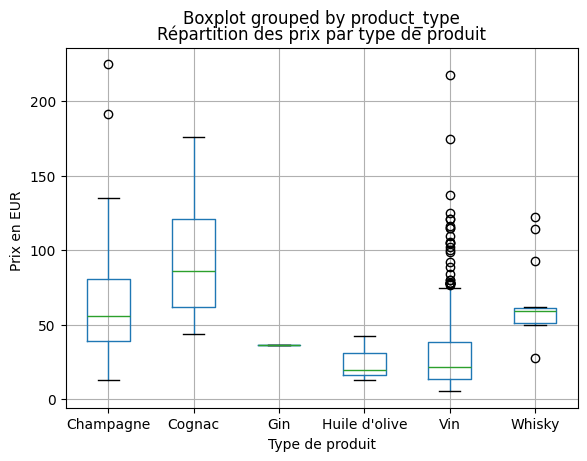

In [184]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
df_merge_web.boxplot(column="price",by="product_type")
plt.title("Répartition des prix par type de produit")
plt.xlabel("Type de produit")
plt.ylabel("Prix en EUR ")
plt.show()

In [185]:
#Autre méthode avec plotly express
px.box(df_merge_web,x="product_type",y="price",title="Répartition des prix par type de produit")

In [186]:
#Nombre de produits par type
df_merge_web["product_type"].value_counts()

,count
product_type,
Vin,657
Champagne,28
Whisky,14
Cognac,8
Huile d'olive,3
Gin,2


La répartition des prix met en évidence un nombre important d'outliers dans la catégorie Vin. Les prix sont principalement concentrés entre 5,2 EUR (lower fence) et 74,8 EUR (upper fence).
Plusieurs outliers sont observés avec un prix maximal de 217,50 EUR.

Dans la catégorie Champagne, les prix sont globalement plus élevés avec une médiane d'environ 56 EUR. Deux outliers sont observées.

Les prix des whiskys sont également élevés, avec une médiane d'environ 59 EUR
La répartition met en évidence quelques outliers, aussi bien vers le bas que vers le haut.

Pour les catégories Cognac, Huile d'olive et Gin, l'effectif est très faible, cette analyse ne permet de tirer de conclusion à ce stade.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [187]:
#Sélection de la cat vin
vin = df_merge_web[df_merge_web["product_type"] == "Vin"].copy()
#Calcul de la moyenne du prix
moyenne = vin["price"].mean()
#Calcul de l'écart-type
ecart_type = vin["price"].std(ddof=0)
#Calcul du Z-score
vin["z_score"] = (vin["price"] - moyenne) / ecart_type
#Seuil de prix dont le Z-score est supérieur à 3
vin.loc[vin["z_score"] > 3, "price"].min()
print( "Il y a {} article(s) dans la catégorie Vin dont le Z-score est supérieur à 3.".format(vin.loc[vin["z_score"] > 3].shape[0]))
#Articles dont le Z-score est supérieur à 3
vin.loc[vin["z_score"] > 3,["product_id", "post_title", "price", "z_score"]]


Il y a 15 article(s) dans la catégorie Vin dont le Z-score est supérieur à 3.


,product_id,post_title,price,z_score
66,4115,Zind-Humbrecht Riesling Grand Cru Rangen De Th...,100.0,3.016834
239,4582,Château de Meursault Puligny-Montrachet 1er Cr...,109.6,3.426232
409,4903,Domaine Des Croix Corton Grand Cru Les Grèves ...,102.3,3.114919
410,4904,Domaine Des Croix Corton Charlemagne Grand Cru...,137.0,4.594724
458,5001,David Duband Charmes-Chambertin Grand Cru 2014,217.5,8.027700
463,5007,Domaine des Comtes Lafon Volnay 1er Cru Santen...,105.0,3.230062
464,5008,Domaine des Comtes Lafon Volnay 1er Cru Santen...,105.0,3.230062
553,5612,Domaine Weinbach Gewurztraminer Grand Cru Furs...,124.8,4.074447
594,5767,Camille Giroud Clos de Vougeot 2016,175.0,6.215259
698,6201,David Duband Chambolle-Musigny 1er Cru Les Sen...,105.6,3.255650


In [188]:
#Sélection de la cat  champagne
champagne = df_merge_web[df_merge_web["product_type"] == "Champagne"].copy()
#Calcul de la moyenne du prix
moyenne = champagne["price"].mean()
#Calcul de l'écart-type
ecart_type = champagne["price"].std(ddof=0)
#Calcul du Z-score
champagne["z_score"] = (champagne["price"] - moyenne) / ecart_type
#Seuil de prix dont le Z-score est supérieur à 3
champagne.loc[champagne["z_score"] > 3, "price"].min()
print( "Il y a {} article(s) dans la catégorie Champagne dont le Z-score est supérieur à 3.".format(champagne.loc[champagne["z_score"] > 3].shape[0]))
#Articles dont le Z-score est supérieur à 3
champagne.loc[champagne["z_score"] > 3,["id_web", "post_title", "price", "z_score"]]

Il y a 1 article(s) dans la catégorie Champagne dont le Z-score est supérieur à 3.


,id_web,post_title,price,z_score
207,15940,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,3.322531


In [189]:
#Sélection de la cat Whisky
whisky = df_merge_web[df_merge_web["product_type"] == "Whisky"].copy()
#Calcul de la moyenne du prix
moyenne = whisky["price"].mean()
#Calcul de l'écart-type
ecart_type = whisky["price"].std(ddof=0)
#Calcul du Z-score
whisky["z_score"] = (whisky["price"] - moyenne) / ecart_type
#Seuil de prix dont le Z-score est supérieur à 3
whisky.loc[whisky["z_score"] > 3, "price"].min()
print( "Il y a {} article(s) dans la catégorie Whisky dont le Z-score est supérieur à 3.".format(whisky.loc[whisky["z_score"] > 3].shape[0]))
#Articles dont le Z-score est supérieur à 3
whisky.loc[whisky["z_score"] > 3,["id_web", "post_title", "price", "z_score"]]

Il y a 0 article(s) dans la catégorie Whisky dont le Z-score est supérieur à 3.


,id_web,post_title,price,z_score


In [190]:
#Sélection de la cat Cognac
Cognac = df_merge_web[df_merge_web["product_type"] == "Cognac"].copy()
#Calcul de la moyenne du prix
moyenne = Cognac["price"].mean()
#Calcul de l'écart-type
ecart_type = Cognac["price"].std(ddof=0)
#Calcul du Z-score
Cognac["z_score"] = (Cognac["price"] - moyenne) / ecart_type
#Seuil de prix dont le Z-score est supérieur à 3
Cognac.loc[Cognac["z_score"] > 3, "price"].min()
print( "Il y a {} article(s) dans la catégorie Cognac dont le Z-score est supérieur à 3.".format(Cognac.loc[Cognac["z_score"] > 3].shape[0]))
#Articles dont le Z-score est supérieur à 3
Cognac.loc[Cognac["z_score"] > 3,["id_web", "post_title", "price", "z_score"]]

Il y a 0 article(s) dans la catégorie Cognac dont le Z-score est supérieur à 3.


,id_web,post_title,price,z_score


In [191]:
# Sélection de la cat Huile d'olive
Huile_olive = df_merge_web[df_merge_web["product_type"] == "Huile d'olive"].copy()
# Calcul de la moyenne du prix
moyenne = Huile_olive["price"].mean()
# Calcul de l'écart-type
ecart_type = Huile_olive["price"].std(ddof=0)
# Calcul du Z-score
Huile_olive["z_score"] = (Huile_olive["price"] - moyenne) / ecart_type
# Seuil de prix dont le Z-score est supérieur à 3
Huile_olive.loc[Huile_olive["z_score"] > 3, "price"].min()
print( "Il y a {} article(s) dans la catégorie Huile d'olive dont le Z-score est supérieur à 3.".format(Huile_olive.loc[Huile_olive["z_score"] > 3].shape[0]))
# Articles dont le Z-score est supérieur à 3
Huile_olive.loc[Huile_olive["z_score"] > 3,["id_web", "post_title", "price", "z_score"]]


Il y a 0 article(s) dans la catégorie Huile d'olive dont le Z-score est supérieur à 3.


,id_web,post_title,price,z_score


In [192]:
# Sélection de la cat Gin
gin = df_merge_web[df_merge_web["product_type"] == "Gin"].copy()
# Calcul de la moyenne du prix
moyenne = gin["price"].mean()
# Calcul de l'écart-type
ecart_type = gin["price"].std(ddof=0)
# Calcul du Z-score
gin["z_score"] = (gin["price"] - moyenne) / ecart_type
# Seuil de prix dont le Z-score est supérieur à 3
gin.loc[gin["z_score"] > 3, "price"].min()
print( "Il y a {} article(s) dans la catégorie Gin dont le Z-score est supérieur à 3.".format(gin.loc[gin["z_score"] > 3].shape[0]))
# Articles dont le Z-score est supérieur à 3
gin.loc[gin["z_score"] > 3,["id_web", "post_title", "price", "z_score"]]


Il y a 0 article(s) dans la catégorie Gin dont le Z-score est supérieur à 3.


,id_web,post_title,price,z_score


Le calcul du Z-score>3 met en évidence l'absence d'outliers dans les catégories Gin, Huile d'olive, Cognac et Whisky.
Ce sont également les catégories les moins représentées en nombre de produits.

La catégorie Champagne présente un seul outlier.

La catégorie Vin est celle qui présente le plus d'outliers.

Cette dispersion des prix peut s'expliquer par la présence de vins de différentes gammes. A ce stade, nous ne pouvons pas conclure à une erreur de prix.

Action métier : transmettre la liste des produits concernés afin de vérifier qu'il ne s'agit pas d'erreurs de prix.


<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

l'exploration de la boite à moustache a mis en évidence la présence d'outliers dans les catégories Vin, Champagne et Whisky. La suite de cette analyse se fera uniquement sur ces 3 catégories

In [193]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
print("VIN")
print(vin["price"].describe())
print("CHAMPAGNE")
print(champagne["price"].describe())
print("WHISKY")
print(whisky["price"].describe())

VIN
count    657.000000
mean      29.258143
std       23.466905
min        5.200000
25%       13.500000
50%       21.800000
75%       38.400000
max      217.500000
Name: price, dtype: float64
CHAMPAGNE
count     28.000000
mean      69.626786
std       47.621631
min       12.650000
25%       39.000000
50%       56.000000
75%       80.375000
max      225.000000
Name: price, dtype: float64
WHISKY
count     14.000000
mean      65.557143
std       26.060129
min       27.500000
25%       51.375000
50%       59.000000
75%       61.450000
max      122.000000
Name: price, dtype: float64


In [194]:
#Calcul IQR. Catégorie Vin
Q1 = vin["price"].quantile(0.25)
Q3 = vin["price"].quantile(0.75)
IQR = Q3 - Q1
#Définir un seuil pour les articles "outliers" en prix
Seuil_bas = Q1 -1.5 * IQR
Seuil_haut = Q3 +1.5 * IQR

In [195]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
outliers_vin = df_merge_web[(df_merge_web["product_type"] == "Vin") & ((df_merge_web["price"] < Seuil_bas) | (df_merge_web["price"] > Seuil_haut))]
nb_outliers = outliers_vin.shape[0]
print("le nombre d'articles outliers dans la catégorie vin est de {}".format(nb_outliers))
nb_total = df_merge_web[df_merge_web["product_type"] == "Vin"].shape[0]
proportion = nb_outliers / nb_total * 100
print("la proportion d'articles 'Vin' outliers est de {:.0f} %".format(proportion))

le nombre d'articles outliers dans la catégorie vin est de 29
la proportion d'articles 'Vin' outliers est de 4 %


In [196]:
#Ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
display(outliers_vin[["id_web","post_title", "price"]])

,id_web,post_title,price
10,15269,Pierre Gaillard Côte Rôtie Rose Pourpre 2017,80.0
36,13074,Château de Vaudieu Châteauneuf-du-Pape L'Avenu...,77.8
66,15382,Zind-Humbrecht Riesling Grand Cru Rangen De Th...,100.0
68,11668,Zind-Humbrecht Pinot Gris Grand Cru Rangen De ...,88.4
71,13217,Zind-Humbrecht Gewurztraminer Grand Cru Rangen...,77.4
132,15720,Lucien Boillot Nuits-Saint-Georges 1er Cru Les...,79.8
239,12857,Château de Meursault Puligny-Montrachet 1er Cr...,109.6
273,791,Marcel Windholtz Eau de Vie de Baie de Houx,76.8
382,14506,Domaine Peyre Rose Clos des Cistes 2008,78.0
409,14805,Domaine Des Croix Corton Grand Cru Les Grèves ...,102.3


La méthode IQR a identifié 29 outliers dans la famille Vin, contre 15 avec la méthode du Z-score.

Les 15 outliers détectés par le Z-score sont également retrouvés avec la méthode IQR, qui identifie donc un plus grand nombre d'outliers.

In [197]:
#Calcul IQR. Catégorie Champagne
Q1_c = champagne["price"].quantile(0.25)
Q3_c = champagne["price"].quantile(0.75)
IQR_c = Q3_c - Q1_c
#Définir un seuil pour les articles "outliers" en prix
Seuil_bas_c = Q1_c -1.5 * IQR_c
Seuil_haut_c = Q3_c +1.5 * IQR_c

In [198]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
outliers_champagne = df_merge_web[(df_merge_web["product_type"] == "Champagne") & ((df_merge_web["price"] < Seuil_bas_c) | (df_merge_web["price"] > Seuil_haut_c))]
nb_outliers_c = outliers_champagne.shape[0]
print("le nombre d'articles outliers dans la catégorie Champagne est de {}".format(nb_outliers_c))
nb_total_c = df_merge_web[df_merge_web["product_type"] == "Champagne"].shape[0]
proportion_c = nb_outliers_c / nb_total_c * 100
print("la proportion d'articles 'Champagne' outliers est de {:.0f}%".format(proportion_c))

le nombre d'articles outliers dans la catégorie Champagne est de 2
la proportion d'articles 'Champagne' outliers est de 7%


In [199]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
display(outliers_champagne[["id_web","post_title", "price"]])

,id_web,post_title,price
207,15940,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0
631,14983,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,191.3


La méthode IQR a identifié 2 outliers dans la famille Champagne, contre 1 avec la méthode du Z-score.

L'outlier detecté par le Z-score est également retrouvé avec la méthode IQR, qui identifie donc un plus grand nombre d'outliers.

In [200]:
#Calcul IQR. Catégorie Whisky
Q1_w = whisky["price"].quantile(0.25)
Q3_w = whisky["price"].quantile(0.75)
IQR_w = Q3_w - Q1_w
#Définir un seuil pour les articles "outliers" en prix
Seuil_bas_w = Q1_w -1.5 * IQR_w
Seuil_haut_w = Q3_w +1.5 * IQR_w

In [201]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
outliers_whisky = df_merge_web[(df_merge_web["product_type"] == "Whisky") & ((df_merge_web["price"] < Seuil_bas_w) | (df_merge_web["price"] > Seuil_haut_w))]
nb_outliers_w = outliers_whisky.shape[0]
print("le nombre d'articles outliers dans la catégorie Whisky est de {}".format(nb_outliers_w))
nb_total_w = df_merge_web[df_merge_web["product_type"] == "Whisky"].shape[0]
proportion_w = nb_outliers_w / nb_total_w * 100
print("la proportion d'articles 'Whisky' outliers est de {:.0f}%".format(proportion_w))

le nombre d'articles outliers dans la catégorie Whisky est de 4
la proportion d'articles 'Whisky' outliers est de 29%


In [202]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
display(outliers_whisky[["id_web","post_title", "price"]])

,id_web,post_title,price
219,11587,Wemyss Malts Blended Scotch Whisky Lord Elcho,27.5
646,14774,Wemyss Malts Single Cask Scotch Whisky Chocola...,93.0
647,14775,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,122.0
648,14773,Wemyss Malts Single Cask Scotch Whisky Chai Ca...,114.0


La méthode IQR a identifié 4 outliers dans la famille Whisky, contre aucun avec la méthode du Z-score. Ces 4 outliers represente 28% du catalogue Whisky. Prudence sur  cette proportion importante car il y'a seulement 14 références de Whisky dans le catalogue web.

Conclusion générale : La méthoque IQR est plus robuste et a permis de détecter un plus grand nombre d'outlier. Toutefois, les données disponibles ne permettent pas de déterminer si ces outliers sont justifiés ou s'ils correspondent à des anomalies. Une comparaison avec les prix d'achat peut néanmoins apporter une piste de vérification.

Recommandation : transmettre cette liste aux équipes métier afin de vérifier la cohérence des prix et de confirmer si ces outliers sont justifiés

Décision Data analyst : ces outliers ne seront pas supprimés du dataset


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

**Hypothèse :** on considère que `price` (prix de vente) est TTC, car c'est ce prix TTC qui est visible par le client sur un site web. Et que `purchase_price` (prix d'achat) est HT, car c'est l'usage courant entre entreprises.

In [203]:
#Création de la colonne Prix HT
df_merge_web["Prix_HT"] = np.where(df_merge_web["product_type"] == "Huile d'olive", df_merge_web["price"] / 1.055,  df_merge_web["price"] / 1.2)
df_merge_all["Prix_HT"] = np.where(df_merge_all["product_type"] == "Huile d'olive", df_merge_all["price"] / 1.055,  df_merge_all["price"] / 1.2 )

In [204]:
##############################
# CA du site web
##############################
#Création d'une colonne calculant le CA par article
df_merge_web["CA_HT"] = df_merge_web["Prix_HT"] * df_merge_web["total_sales"]
Total_CA = df_merge_web["CA_HT"].sum()
#Calculer la somme de la colonne "ca_par_article"
print ("Le chiffre d'affaire HT du site web sur la période analysée est de {} EUR".format(round(Total_CA,)))

Le chiffre d'affaire HT du site web sur la période analysée est de 119494 EUR


In [205]:
###############################
# Palmarès des articles en CA #
###############################

#Tri dans l'ordre décroissant du CA du dataset df_merge
df_merge_web = df_merge_web.sort_values("CA_HT", ascending=False)
#Réinitialisation de l'index du dataset par un reset_index
df_merge_web = df_merge_web.reset_index()
#TOP 10 articles en CA
Top_10_CA = df_merge_web.sort_values(("CA_HT"), ascending=False).head(10)

In [206]:
display(Top_10_CA)

,index,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title,Prix_HT,CA_HT
0,207,4352,1,225.0,0,outofstock,137.81,15940,11.0,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,187.500000,2062.500000
1,631,5892,1,191.3,98,instock,116.06,14983,6.0,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,159.416667,956.500000
2,208,4353,1,79.5,127,instock,45.91,12587,14.0,Champagne,Champagne Egly-Ouriet Grand Cru Brut Rosé,66.250000,927.500000
3,626,5826,1,41.2,34,instock,21.71,15325,20.0,Vin,Agnès Levet Côte Rôtie Améthyste 2017,34.333333,686.666667
4,704,6212,1,115.0,16,instock,59.42,13996,7.0,Vin,Domaine des Comtes Lafon Volnay 1er Cru Santen...,95.833333,670.833333
5,473,5026,1,86.8,101,instock,50.13,13913,9.0,Champagne,Champagne Agrapart &amp; Fils Minéral Extra Br...,72.333333,651.000000
6,464,5008,1,105.0,12,instock,56.42,11602,7.0,Vin,Domaine des Comtes Lafon Volnay 1er Cru Santen...,87.500000,612.500000
7,594,5767,1,175.0,12,instock,90.42,15185,4.0,Vin,Camille Giroud Clos de Vougeot 2016,145.833333,583.333333
8,693,6126,1,135.0,138,instock,80.33,14923,5.0,Champagne,Champagne Gosset Célébris Vintage 2007,112.500000,562.500000
9,472,5025,1,112.0,136,instock,68.60,13914,6.0,Champagne,Champagne Agrapart &amp; Fils L'Avizoise Extra...,93.333333,560.000000


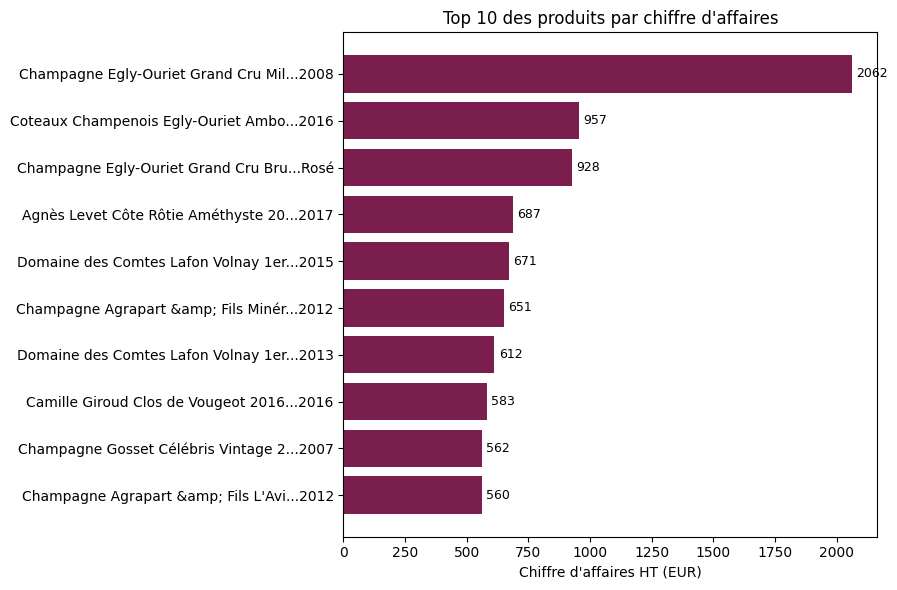

In [207]:
#Top 10 des produits par chiffre d'affaires
Top_10_CA = Top_10_CA.head(10).copy()

#Création du libellé : 25 premiers caractères + année
Top_10_CA["label"] = (Top_10_CA["post_title"].str[:35] + "..."+ Top_10_CA["post_title"].str[-4:])

#Création du graphique
fig, ax = plt.subplots(figsize=(9, 6))

#Barres horizontales
barres = ax.barh( Top_10_CA["label"], Top_10_CA["CA_HT"], color="#7A1F4D")

#Valeurs au bout des barres
ax.bar_label( barres, fmt="%.0f", padding=3, fontsize=9)

#Plus grande valeur en haut
ax.invert_yaxis()

#Titres
ax.set_title("Top 10 des produits par chiffre d'affaires")
ax.set_xlabel("Chiffre d'affaires HT (EUR)")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [208]:
#############################
# 20 / 80 en CA
#############################

#Création colonne de la part du CA de la ligne dans le dataset
df_merge_web["Part_CA_%"] = df_merge_web["CA_HT"] / Total_CA *100
df_merge_web.head()
#Création colonne réalisant la somme cumulative de la colonne précedemment créée
df_merge_web["Part_CA_%_cumulé"] = df_merge_web["Part_CA_%"].cumsum()
#Nombre d'articles représentant 80% du CA
print ("le nombre d'article représentant 80% du CA HT est {}".format(df_merge_web.loc[df_merge_web["Part_CA_%_cumulé"]<=80].shape[0]))

print ("Cela représente {:.0f} % du catalogue web".format(df_merge_web.loc[df_merge_web["Part_CA_%_cumulé"]<80].shape[0]/df_merge_web.shape[0]*100))

le nombre d'article représentant 80% du CA HT est 433
Cela représente 61 % du catalogue web


61% des articles du catalogue web représente 80% du CA. Cela signifie que les ventes sont moins concentré que dans la distribution pareto 20/80. Le CA ici est réparti sur un plus grand nombre de référence.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [209]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Tri dans l'ordre décroissant de quantités vendues du dataset df_merge
df_merge_web = df_merge_web.sort_values("total_sales", ascending=False)
#Réinitialisation de l'index du dataset par un reset_index
df_merge_web = df_merge_web.reset_index()
#Affichage des 20 premiers articles en quantité
Top_20_Sales = df_merge_web.sort_values(("total_sales"), ascending=False).head(20)

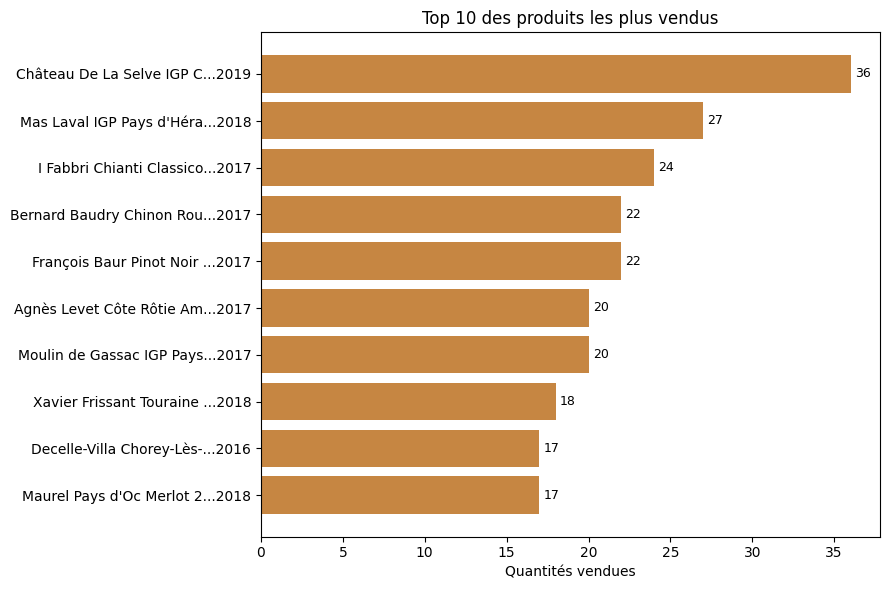

In [210]:
#Top 10 des produits les plus vendus
Top_10_Sales = Top_20_Sales.head(10).copy()

#Création du libellé : 25 premiers caractères + année
Top_10_Sales["label"] = (Top_10_Sales["post_title"].str[:25] + "..." + Top_10_Sales["post_title"].str[-4:])

#Création du graphique
fig, ax = plt.subplots(figsize=(9, 6))

#Barres horizontales
barres = ax.barh(Top_10_Sales["label"],Top_10_Sales["total_sales"], color="#C68642")

#Valeurs au bout des barres
ax.bar_label(barres, fmt="%.0f", padding=3, fontsize=9)

#Plus grande valeur en haut
ax.invert_yaxis()

#Titres
ax.set_title("Top 10 des produits les plus vendus")
ax.set_xlabel("Quantités vendues")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [211]:
#############################
# Calculer le 20 / 80 en sales #
#############################

#Création d'une colonne calculant la part en quantité de la ligne dans le dataset
total_sales = df_merge_web["total_sales"].sum()
print ("Les quantité total vendue sur la période analysée est de {} unités".format(total_sales))
df_merge_web["total_sales_%"] = df_merge_web["total_sales"] / total_sales *100

#Création d' une colonne réalisant la somme cumulative de la colonne précedemment créée
df_merge_web["Part_sales_%_cumulé"] = df_merge_web["total_sales_%"].cumsum()
#Calcul du nombre d'articles représentant 80% des ventes en quantité
print ("le nombre d'article représentant 80% des ventes en quantité est de {:.0f}".format(df_merge_web.loc[df_merge_web["Part_sales_%_cumulé"]<=80].shape[0]))
#Affichage de la proportion que représente ce groupe d'articles dans le catalogue entier du site web
print ("Cela représente {:.0f} % du catalogue web".format(df_merge_web.loc[df_merge_web["Part_sales_%_cumulé"]<=80].shape[0]/df_merge_web.shape[0]*100))

Les quantité total vendue sur la période analysée est de 5743.0 unités
le nombre d'article représentant 80% des ventes en quantité est de 432
Cela représente 61 % du catalogue web


Comme pour le chiffre d'affaires, 61 % des références représentent 80 % des quantités vendues.
Les ventes ne dépendent pas uniquement de quelques articles mais d'un grand nombre de références qui contribuent au chiffre d'affaires.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [212]:
######################################
# Calcul de la couverture de stock #
######################################

#Création de la colonne Couverture de stock
df_merge_web["Couverture_stock"] = ((df_merge_web["stock_quantity"] / df_merge_web["total_sales"]))

#Remplacement des "inf" par 0
df_merge_web.replace([np.inf, -np.inf], 0, inplace=True)

#Tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge
df_merge_web = df_merge_web.sort_values("Couverture_stock", ascending=False)
Flop_20_couverture_stock = df_merge_web.head(20)


In [213]:
#Articles avec 0 stock et des ventes
rupture = df_merge_web.loc[(df_merge_web["Couverture_stock"] == 0) & (df_merge_web["total_sales"] != 0)]
rupture.head()

,level_0,index,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title,Prix_HT,CA_HT,Part_CA_%,Part_CA_%_cumulé,total_sales_%,Part_sales_%_cumulé,Couverture_stock
12,423,394,4870,1,9.3,0,outofstock,4.81,16149,16.0,Vin,Triennes IGP Méditerranée Rosé 2019,7.750000,124.000000,0.103771,79.006641,0.278600,4.736201,0.0
526,614,257,4612,1,20.6,0,outofstock,10.22,15038,5.0,Vin,Gilbert Picq Chablis Vieilles Vignes 2017,17.166667,85.833333,0.071831,95.757031,0.087063,90.092286,0.0
682,640,542,5565,1,92.0,0,outofstock,46.11,19822,1.0,Vin,Tempier Bandol Cabassaou 2017,76.666667,76.666667,0.064160,97.544432,0.017413,99.912937,0.0
20,491,154,4241,1,8.9,0,outofstock,4.37,14725,15.0,Vin,Parcé Frères IGP Côtes Catalanes Hommage à Fer...,7.416667,111.250000,0.093101,85.709711,0.261188,6.912763,0.0
664,603,747,6632,1,52.7,0,outofstock,26.41,15794,2.0,Vin,Weingut Besson-Strasser Zürich Pinot Noir Chlo...,43.916667,87.833333,0.073505,94.961241,0.034825,99.390562,0.0


In [214]:
print ("il y'a {} article(s)s qui ont des ventes dans le mois en cours mais qui sont aussi en rupture c'est à dire le stock est = à 0 à la date de l'extraction".format(rupture.shape[0]))

il y'a 22 article(s)s qui ont des ventes dans le mois en cours mais qui sont aussi en rupture c'est à dire le stock est = à 0 à la date de l'extraction


/tmp/ipykernel_2586/3614795980.py:21: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



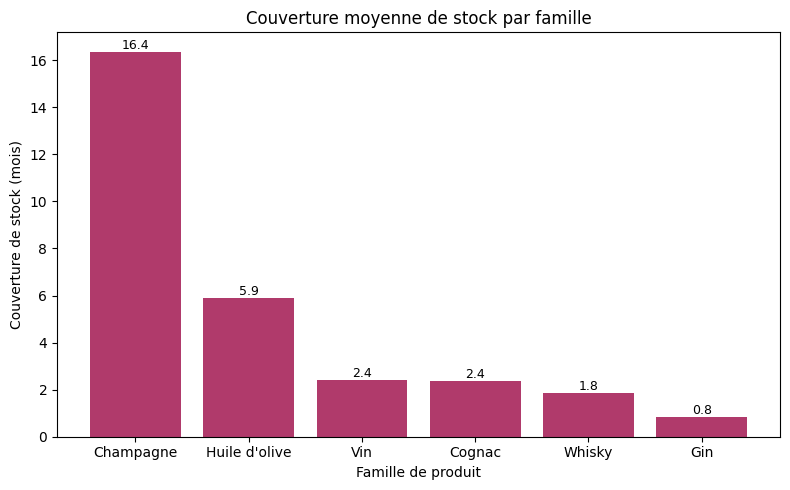

In [215]:
#Couverture moyenne de stock par famille
df_couverture_famille = (df_merge_web.groupby("product_type", as_index=False)["Couverture_stock"].mean().sort_values("Couverture_stock", ascending=False))

#Moyenne globale
moyenne_globale = df_couverture_famille["Couverture_stock"].mean()

#Graphique
fig, ax = plt.subplots(figsize=(8,5))

#Barres
barres = ax.bar(df_couverture_famille["product_type"],df_couverture_famille["Couverture_stock"],color="#B03A6B")
# Valeurs au-dessus des barres
ax.bar_label(barres, fmt="%.1f", fontsize=9)

#Titres
ax.set_title("Couverture moyenne de stock par famille")
ax.set_ylabel("Couverture de stock (mois)")
ax.set_xlabel("Famille de produit")

#Légende
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [216]:
#Création des classes de couverture de stock
df_merge_web["Classe_couverture"] = "> 6 mois"

#Affectation des classes
df_merge_web.loc[df_merge_web["Couverture_stock"] <= 6, "Classe_couverture"] = "3 à 6 mois"
df_merge_web.loc[df_merge_web["Couverture_stock"] <= 3, "Classe_couverture"] = "2 à 3 mois"
df_merge_web.loc[df_merge_web["Couverture_stock"] < 2, "Classe_couverture"] = "< 2 mois"
df_merge_web.loc[df_merge_web["Couverture_stock"] == 0, "Classe_couverture"] = "0 mois"

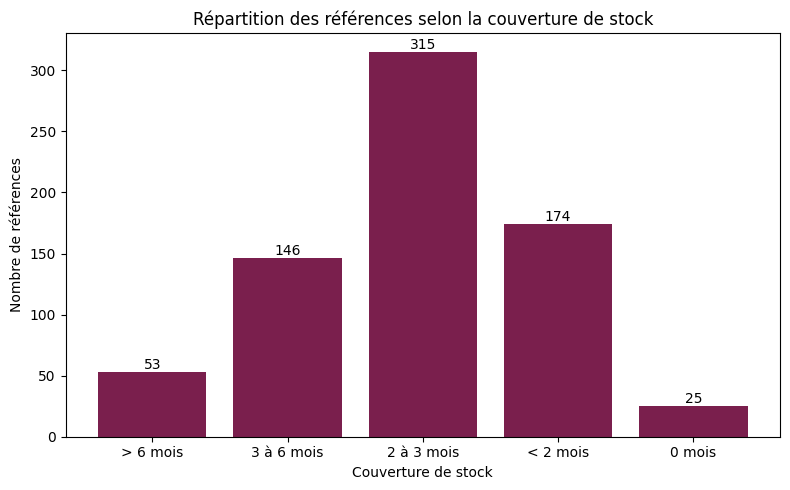

In [217]:
#Comptage du nombre de références par classe
df_couverture = (df_merge_web["Classe_couverture"].value_counts(sort=False).reset_index())
df_couverture.columns = ["Couverture","Nombre de références"]

#Graphique
fig, ax = plt.subplots(figsize=(8,5))
barres = ax.bar(df_couverture["Couverture"],df_couverture["Nombre de références"],color="#7A1F4D")

#Affichage des valeurs
ax.bar_label(barres)
ax.set_title("Répartition des références selon la couverture de stock")
ax.set_xlabel("Couverture de stock")
ax.set_ylabel("Nombre de références")

plt.tight_layout()
plt.show()

In [218]:
df_merge_web.head()

,level_0,index,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,total_sales,product_type,post_title,Prix_HT,CA_HT,Part_CA_%,Part_CA_%_cumulé,total_sales_%,Part_sales_%_cumulé,Couverture_stock,Classe_couverture
613,241,73,4142,1,53.0,125,instock,32.15,11641,4.0,Champagne,Champagne Gosset Grand Millésime 2006,44.166667,176.666667,0.147846,56.477255,0.069650,96.865750,31.250000,> 6 mois
519,8,693,6126,1,135.0,138,instock,80.33,14923,5.0,Champagne,Champagne Gosset Célébris Vintage 2007,112.500000,562.500000,0.470736,6.455010,0.087063,89.482849,27.600000,> 6 mois
625,400,210,4356,1,51.6,81,instock,31.00,12585,3.0,Champagne,Champagne Egly-Ouriet Premier Cru Les Vignes d...,43.000000,129.000000,0.107955,76.571507,0.052238,97.510012,27.000000,> 6 mois
543,105,205,4348,1,59.0,125,instock,34.76,12586,5.0,Champagne,Champagne Egly-Ouriet Grand Cru Brut Tradition,49.166667,245.833333,0.205729,33.032968,0.087063,91.572349,25.000000,> 6 mois
655,571,77,4148,1,37.5,71,instock,21.88,1364,3.0,Champagne,Champagne Mailly Grand Cru Brut Rosé,31.250000,93.750000,0.078456,92.534614,0.052238,99.077137,23.666667,> 6 mois


- Analyse surstock :
Le champagne a une forte couverture de stock, de plus de 16 mois. L'huile d'olive également avec près de 6 mois de stock.
Il serait intéressant d'analyser les articles en surstock, exemple la réf 11641 à une couverture de stock de plus de 30 mois, soit plus de 2.5 ans de couverture de stock.

- Analyse Rupture :
En revanche le Gin a une couverture de stock inférieur à 0.8 mois.
Alerte Rupture également sur 22 articles qu'il faudra surveiller, car des ventes sont enregistrées sur le mois en cours alors que le stock est à 0 à la date de l'extraction.

- Recommandation : ces données sont à croiser avec le lead time standard des articles afin d"évaluer la criticité des surstocks ou ruptures et de prioriser les actions

In [219]:
####################################
# Valorisation des stocks en euros #
####################################
#Cette analyse des stocks sera réalisée à partir du DataFrame complet : df_merge_all afin d'avoir également une évaluation du stock  sur les articles non référencés en ligne

#Création de la colonne Valorisation des stocks en euros
df_merge_all["Valorisation_stock_EUR"] = df_merge_all["stock_quantity"] * df_merge_all["purchase_price"]

#Calcule de la somme de la colonne "Valorisation_stock_euros"
Total_Valorisation_stock_EUR = df_merge_all["Valorisation_stock_EUR"].sum()
print ("Le montant total de la valeur des stocks sur la période analysée est de {:.0f} EUR HT".format(df_merge_all["Valorisation_stock_EUR"].sum()))

Le montant total de la valeur des stocks sur la période analysée est de 298540 EUR HT


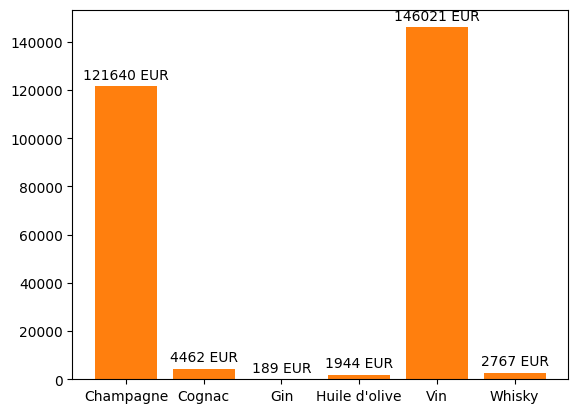

In [220]:
#Graphique valorisation du stock par type de produit
df_stock = (df_merge_all.groupby("product_type", as_index=False)["Valorisation_stock_EUR"].sum())
fig, ax = plt.subplots()
ax.bar(df_stock["product_type"], df_stock["Valorisation_stock_EUR"])
barres = ax.bar(df_stock["product_type"],df_stock["Valorisation_stock_EUR"])
ax.bar_label(barres, fmt="%.0f EUR", padding=3)
plt.show()

In [221]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calcule de la somme de la colonne stock quantity
df_merge_all["stock_quantity"].sum()
print ("La quantité total des stocks sur la période analysée est de {} unités ".format(df_merge_all["stock_quantity"].sum()))

La quantité total des stocks sur la période analysée est de 17803 unités 


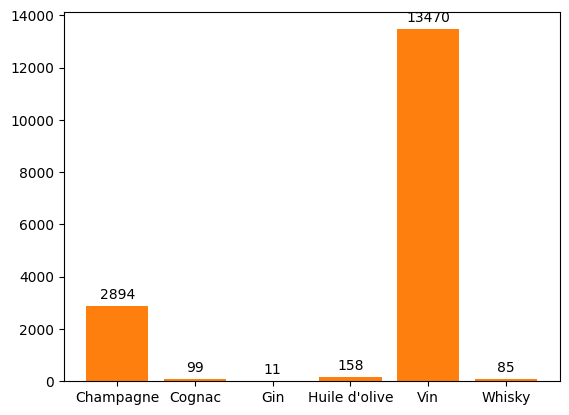

In [222]:
#Graphique quantité en stock par type de produit
df_stock_quantity = (df_merge_all.groupby("product_type", as_index=False)["stock_quantity"].sum())
fig, ax = plt.subplots()
ax.bar(df_stock_quantity["product_type"],df_stock_quantity["stock_quantity"])
barres = ax.bar(df_stock_quantity["product_type"],df_stock_quantity["stock_quantity"])
ax.bar_label(barres, fmt="%.0f", padding=3)
plt.show()

In [223]:
# Quantité et valorisation selon le statut onsale_web = 0
print("Le nombre de références non vendues sur le web est de {}.".format(df_merge_all[df_merge_all["onsale_web"] == 0].shape[0]))
print("La quantité en stock des références non vendues sur le web est de {} unités.".format(df_merge_all.loc[df_merge_all["onsale_web"] == 0, "stock_quantity"].sum()))
print("La valorisation du stock des références non vendues sur le web est de {:.0f} €.".format(df_merge_all.loc[df_merge_all["onsale_web"] == 0, "Valorisation_stock_EUR"].sum()))

Le nombre de références non vendues sur le web est de 105.
La quantité en stock des références non vendues sur le web est de 1096 unités.
La valorisation du stock des références non vendues sur le web est de 21315 €.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse des stocks vs CA </h3>
</div>

In [224]:
#CA du mois HT
print ("Le chiffre d'affaire HT du mois est de {:.0f} EUR".format(Total_CA,))
#Valeur stock du mois HT
print ("Le montant total de la valeur des stocks sur la période analysée est de {:.0f} EUR HT".format(df_merge_all["Valorisation_stock_EUR"].sum()))
#Couverture de stock
Couverture_globale_mois = Total_Valorisation_stock_EUR / Total_CA
print ("LA couverture de stock est de {:.1f} mois".format(Couverture_globale_mois))

Le chiffre d'affaire HT du mois est de 119494 EUR
Le montant total de la valeur des stocks sur la période analysée est de 298540 EUR HT
LA couverture de stock est de 2.5 mois


Le stock du mois analysé représent 2.5 mois d'activité. Afin de vérifier si ce stock est suffisant, il serait interessant de le croiser avec le délai d'approvisionnement des produits.

les produits qui ne sont pas vendus en ligne et qui ont un statut (onsale_web = 0) représentent 1 096 unités valorisées à plus de 21 k€.

Recommandation : ces stocks nécessitent une analyse métier afin de vérifier le bon paramétrage du statut "onsale_web". Si le statut est conforme, évaluer la mise en place d'un plan d'action pour écouler ces stocks.

Vin : beaucoup de stock et beaucoup de valeur.

Ce qui est intéressant dans l'analyse c'est le Champagne, qui représente une faible part des quantités stockées, mais une part beaucoup plus importante de la valeur du stock.

Cognac : très peu de quantité, mais une valeur non négligeable.

Huile d'olive et Gin : faibles sur les deux indicateurs.

Recommandation : conserver un historique des stocks (valorisation et qté ) afin de pouvoir analyser leur évolution dans le temps.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [225]:
############################
# Analyse du taux de marge #
############################

#Cette analyse de la marge sera réalisée à partir du DataFrame complet : df_merge_all afin d'avoir également une évaluation des marges sur l'ensemble du catalogue

#Création de la colonne Taux de marge
df_merge_all["Taux de marge %"] = (df_merge_all["Prix_HT"] - df_merge_all["purchase_price"])*100 /df_merge_all["purchase_price"]
#Affichage de la ligne avec un taux de marge inférieur à 0
df_merge_all.loc[df_merge_all["Taux de marge %"]<0,["product_id","id_web","onsale_web","stock_quantity","product_type","purchase_price","Prix_HT","Taux de marge %"]]

,product_id,id_web,onsale_web,stock_quantity,product_type,purchase_price,Prix_HT,Taux de marge %
209,4355,12589,1,97,Champagne,77.48,10.541667,-86.394338
390,4864,15154,0,0,NaN,9.99,6.916667,-30.764097
720,6324,<NA>,0,18,NaN,99.00,76.666667,-22.558923
812,7196,<NA>,0,55,NaN,31.20,25.833333,-17.200855


In [226]:
#Afficher le prix minimum de la colonne "taux_marge"
print ("le taux de marge minimum est de {:.0f} %".format(df_merge_all["Taux de marge %"].min()))

#Afficher le prix maximum de la colonne "taux_marge"
print ("le taux de marge maximum est de {:.0f} %".format(df_merge_all["Taux de marge %"].max()))

le taux de marge minimum est de -86 %
le taux de marge maximum est de 91 %


**ANOMALIE 9** : marge négative détectée sur 4 articles dont 1 en vente en ligne.

Action métier : vérifier en priorité la cohérence entre le prix d'achat et le prix de vente de l'article en ligne car la marge calculée est négative. Vérifier dans un second temps les prix des 3 articles restants, notamment 2 articles avec du stock.

Attention limite de l'analyse : En l'absence d'information sur le type de produit (product_type = NaN), une TVA de 20 % a été appliquée par défaut.

Action Data Analyst : Création d'un dataframe avec les taux positifs pour la suite de l'analyse à partir du df_merge_web

In [227]:
#Création d'un dataframe avec les taux positifs - La suite de l'analyse est réalisée à partir du DataFrame df_merge_web, afin d'obtenir une analyse des article en vente uniquement.

#Création de la colonne Taux de marge
df_merge_web["Taux de marge %"] = (df_merge_web["Prix_HT"] - df_merge_web["purchase_price"])*100 /df_merge_web["purchase_price"]
#Création d'un dataframe avec les taux positifs
df_analyse_marge = df_merge_web.loc[ df_merge_web["Taux de marge %"] >0, ["product_id","price","stock_quantity","stock_status", "purchase_price","id_web","product_type","post_title","Prix_HT","Taux de marge %" ]]
df_analyse_marge = df_analyse_marge.sort_values( by="Taux de marge %",ascending=True)

#Calcul du taux de marge moyen :
print ("le taux de marge moyen est de {:.0f} %".format(df_analyse_marge["Taux de marge %"].mean()))
#Calcul du taux de marge minimum :
print ("le taux de marge minimum est de {:.0f} %".format(df_analyse_marge["Taux de marge %"].min()))
#Calcul du taux de marge maximum :
print ("le taux de marge maximum est de {:.0f} %".format(df_analyse_marge["Taux de marge %"].max()))

le taux de marge moyen est de 61 %
le taux de marge minimum est de 31 %
le taux de marge maximum est de 91 %


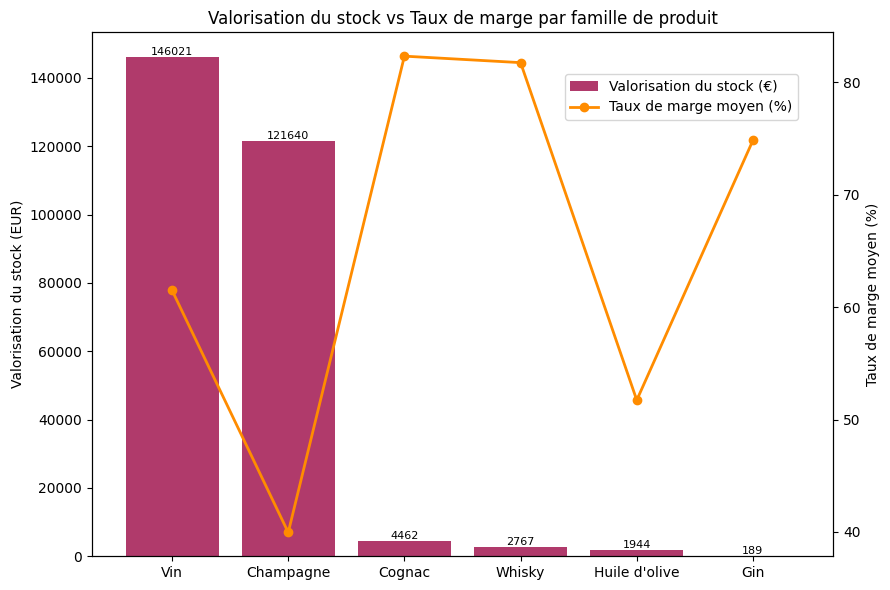

In [228]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
df_analyse_marge_moyen = (df_analyse_marge.groupby("product_type")["Taux de marge %"].mean().reset_index())

#fusion (valorisation par famille + marge par famille) sur product_type
df_marge_vs_stock = df_stock.merge(df_analyse_marge_moyen, on="product_type")

#tri
df_marge_vs_stock = df_marge_vs_stock.sort_values("Valorisation_stock_EUR", ascending=False)

fig, ax1 = plt.subplots(figsize=(9,6))

#Barres : valorisation du stock
barres1 = ax1.bar(df_marge_vs_stock["product_type"], df_marge_vs_stock["Valorisation_stock_EUR"], color="#B03A6B", label="Valorisation du stock (€)")
ax1.bar_label(barres1, fmt="%.0f", fontsize=8)
ax1.set_ylabel("Valorisation du stock (EUR)")

#courbe : taux de marge
ax2 = ax1.twinx()
ax2.plot(df_marge_vs_stock["product_type"], df_marge_vs_stock["Taux de marge %"], color="darkorange", marker="o", linewidth=2, label="Taux de marge moyen (%)")
ax2.set_ylabel("Taux de marge moyen (%)")

ax1.set_title("Valorisation du stock vs Taux de marge par famille de produit")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))

plt.tight_layout()
plt.show()

Cognac et Whisky ont les meilleures marges (82%) mais presque pas de stock.
À l'inverse, Vin et Champagne représentent 97% de la valeur du stock, avec des marges plus faibles (61% et 40%).

**Alerte Champagne :** couverture de stock la plus longue (16,4 mois) et marge la plus basse (40%) --> famille prioritaire à revoir (achat, prix, ou déstockage).

**Vin :** beaucoup de stock, mais marge dans la moyenne (61%) --> à surveiller, sans urgence.

**Conclusion :** le stock le plus important n'est pas forcément le plus rentable.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

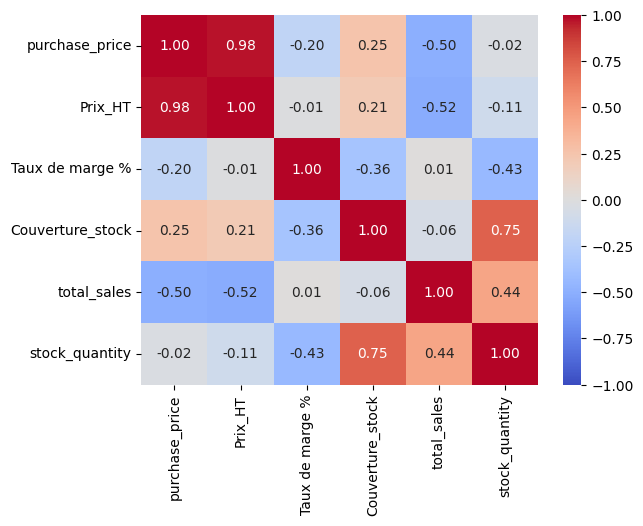

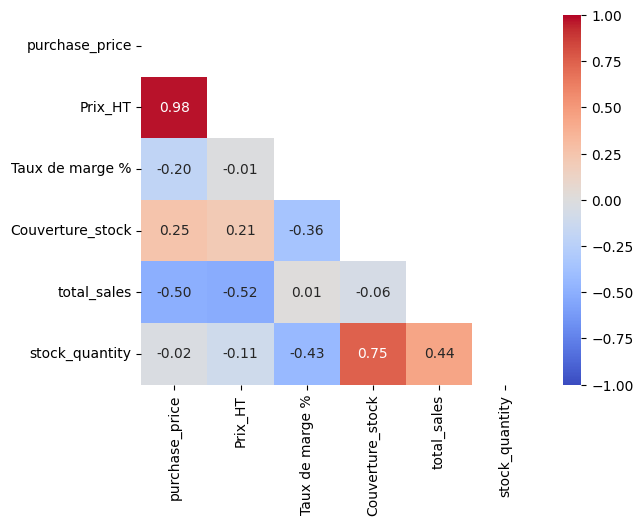

In [229]:
############################
# Analyse des corrélations #
############################


#Création d'une heatmap de corrélation :
df_selection =  df_merge_web[["purchase_price","Prix_HT", "Taux de marge %", "Couverture_stock","total_sales","stock_quantity"]]

#Création de la matrice de corrélation
mat_corr = df_selection.corr()

#Création du heatmap
sns.heatmap(mat_corr, annot=True, cmap='coolwarm',fmt=".2f",vmin=-1, vmax=1)
plt.show()


#Générer un masque pour masquer la moitié supérieure
mask = np.triu(np.ones_like(mat_corr, dtype=bool))

# Configurer la figure matplotlib
#plt.figure(figsize=(10, 8))

# Créer la heatmap de corrélation avec le masque
# sns.heatmap(mat_corr, mask=mask, annot=True, fmt=".1%")
sns.heatmap(mat_corr, mask=mask, annot=True, cmap='coolwarm', fmt=".2f",vmin=-1, vmax=1)

# Afficher le graphique
plt.show()

**Prix / Ventes :** -0.52, corrélation négative modérée. Les produits les plus chers se vendent un peu moins.

**Stock / Ventes :** 0.44, corrélation positive modérée. Les produits qui se vendent le plus ont un stock plus important.

**Marge / Quantité en stock :** -0.43, et **Marge / Couverture de stock :** -0.36.
Ces deux corrélations confirment, sur l'ensemble du catalogue, ce qu'on avait observé sur Champagne et Cognac : les produits à forte marge sont détenus en petites quantités et tournent plus vite, contrairement aux produits à faible marge qui s'accumulent en stock.

**Marge / Ventes :** 0.01, aucun lien. Augmenter la marge ne semble pas pénaliser le volume de ventes.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [230]:
(df_merge_web.to_excel("bottleneck_web_oct.xlsx", index=False))
